<a href="https://colab.research.google.com/github/rithishacs24-lab/BIS-LAB/blob/main/parallel%20cellular.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Employee Preferences:
Employee 1: Shift 2
Employee 2: Shift 0
Employee 3: Shift 2
Employee 4: Shift 2
Employee 5: Shift 0
Employee 6: Shift 0
Employee 7: Shift 2
Employee 8: Shift 1
Employee 9: Shift 2
Employee 10: Shift 2
Iteration   1 | Best Fitness: 331.52
Iteration   2 | Best Fitness: 331.52
Iteration   3 | Best Fitness: 321.12
Iteration   4 | Best Fitness: 316.52
Iteration   5 | Best Fitness: 316.12
Iteration   6 | Best Fitness: 301.52
Iteration   7 | Best Fitness: 301.52
Iteration   8 | Best Fitness: 296.12
Iteration   9 | Best Fitness: 286.52
Iteration  10 | Best Fitness: 286.52
Iteration  11 | Best Fitness: 286.12
Iteration  12 | Best Fitness: 271.52
Iteration  13 | Best Fitness: 271.52
Iteration  14 | Best Fitness: 271.52
Iteration  15 | Best Fitness: 271.52
Iteration  16 | Best Fitness: 271.52
Iteration  17 | Best Fitness: 271.52
Iteration  18 | Best Fitness: 271.12
Iteration  19 | Best Fitness: 271.12
Iteration  20 | Best Fitness: 266.12
Iteration  21 | Best Fitness: 266.12


,Day,Morning,Evening,Night
0,Monday,"Employee 2, Employee 5","Employee 3, Employee 8","Employee 7, Employee 4"
1,Tuesday,"Employee 6, Employee 5","Employee 4, Employee 1","Employee 10, Employee 9"
2,Wednesday,"Employee 6, Employee 2","Employee 10, Employee 8","Employee 7, Employee 4"
3,Thursday,"Employee 5, Employee 6","Employee 8, Employee 10","Employee 9, Employee 3"
4,Friday,"Employee 10, Employee 2","Employee 1, Employee 4","Employee 9, Employee 7"
5,Saturday,"Employee 5, Employee 6","Employee 10, Employee 8","Employee 3, Employee 9"
6,Sunday,"Employee 5, Employee 2","Employee 10, Employee 1","Employee 7, Employee 3"



EMPLOYEE WORKLOAD:


,Employee,Weekly Shifts
0,Employee 1,3
1,Employee 2,4
2,Employee 3,4
3,Employee 4,4
4,Employee 5,5
5,Employee 6,4
6,Employee 7,4
7,Employee 8,4
8,Employee 9,4
9,Employee 10,6



========== VALIDATION ==========
Total assignments: 42
Expected assignments: 42
Daily scheduling conflicts: 0
Employees outside weekly shift limits: 2
All shifts have exactly 2 employees: True
All daily assignments are conflict-free: True


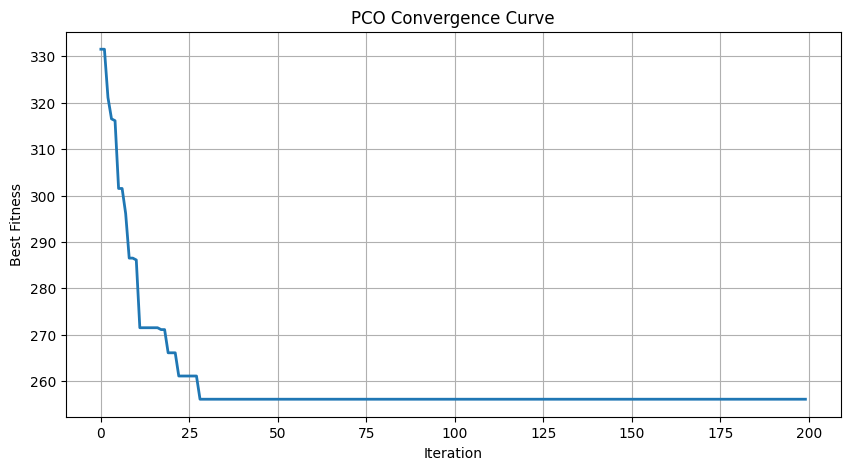

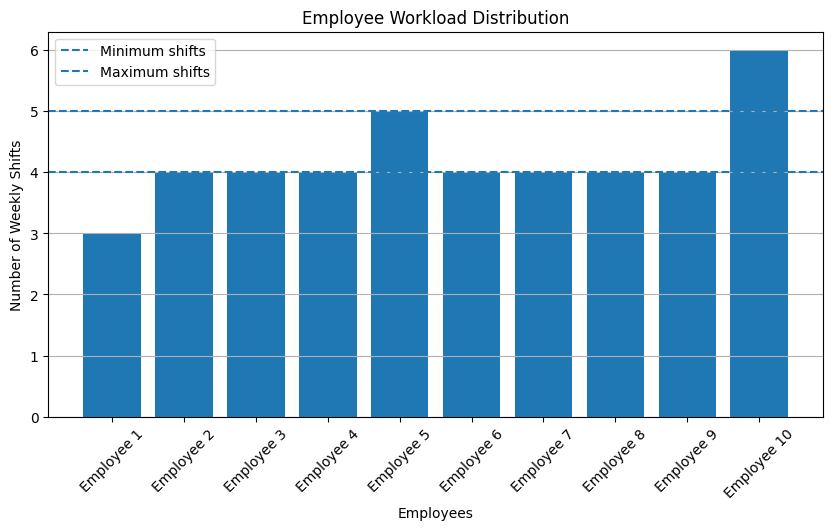


Final Fitness: 256.12
Workload Variance: 0.5599999999999999

Excel file generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

# ============================================================
# PARALLEL CELLULAR OPTIMIZATION (PCO)
# EMPLOYEE SHIFT SCHEDULING
# GOOGLE COLAB IMPLEMENTATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display

# ------------------------------------------------------------
# 1. PROBLEM PARAMETERS
# ------------------------------------------------------------

NUM_EMPLOYEES = 10
NUM_DAYS = 7
NUM_SHIFTS = 3
EMPLOYEES_PER_SHIFT = 2

MIN_SHIFTS = 4
MAX_SHIFTS = 5

NUM_CELLS = 8
POPULATION_PER_CELL = 10
MAX_ITERATIONS = 200

np.random.seed(42)
random.seed(42)

# Each day has 6 employee positions:
# 3 shifts x 2 employees

TOTAL_SLOTS = NUM_DAYS * NUM_SHIFTS * EMPLOYEES_PER_SHIFT

# ------------------------------------------------------------
# 2. EMPLOYEE SHIFT PREFERENCES
# ------------------------------------------------------------

# 0 = Morning
# 1 = Evening
# 2 = Night

preferences = np.random.randint(
    0, NUM_SHIFTS,
    size=NUM_EMPLOYEES
)

print("Employee Preferences:")
for i in range(NUM_EMPLOYEES):
    print(f"Employee {i+1}: Shift {preferences[i]}")

# ------------------------------------------------------------
# 3. FITNESS FUNCTION
# ------------------------------------------------------------

def evaluate_schedule(schedule):

    workload = np.zeros(NUM_EMPLOYEES)
    preference_penalty = 0
    conflict_penalty = 0

    schedule = schedule.reshape(
        NUM_DAYS,
        NUM_SHIFTS,
        EMPLOYEES_PER_SHIFT
    )

    # Check daily employee conflicts
    for day in range(NUM_DAYS):

        daily_employees = []

        for shift in range(NUM_SHIFTS):

            employees = schedule[day, shift]

            for emp in employees:
                workload[emp] += 1
                daily_employees.append(emp)

                if preferences[emp] != shift:
                    preference_penalty += 1

        # Penalize employees assigned multiple shifts
        conflict_penalty += (
            len(daily_employees) - len(set(daily_employees))
        )

    # Workload penalties
    workload_penalty = np.sum(
        np.maximum(MIN_SHIFTS - workload, 0) +
        np.maximum(workload - MAX_SHIFTS, 0)
    )

    # Workload fairness
    fairness_penalty = np.var(workload)

    # Combined fitness
    fitness = (
        1000 * conflict_penalty +
        100 * workload_penalty +
        5 * preference_penalty +
        2 * fairness_penalty
    )

    return fitness


# ------------------------------------------------------------
# 4. GENERATE VALID INITIAL SCHEDULE
# ------------------------------------------------------------

def generate_schedule():

    schedule = np.zeros(
        (NUM_DAYS, NUM_SHIFTS, EMPLOYEES_PER_SHIFT),
        dtype=int
    )

    for day in range(NUM_DAYS):

        selected = np.random.choice(
            NUM_EMPLOYEES,
            size=NUM_SHIFTS * EMPLOYEES_PER_SHIFT,
            replace=False
        )

        schedule[day] = selected.reshape(
            NUM_SHIFTS,
            EMPLOYEES_PER_SHIFT
        )

    return schedule.flatten()


# ------------------------------------------------------------
# 5. LOCAL SEARCH
# ------------------------------------------------------------

def local_search(schedule, attempts=15):

    best = schedule.copy()
    best_fitness = evaluate_schedule(best)

    for _ in range(attempts):

        candidate = best.copy()

        # Swap two employee assignments
        i, j = np.random.choice(
            TOTAL_SLOTS, 2, replace=False
        )

        candidate[i], candidate[j] = (
            candidate[j], candidate[i]
        )

        candidate_fitness = evaluate_schedule(candidate)

        if candidate_fitness < best_fitness:
            best = candidate
            best_fitness = candidate_fitness

    return best, best_fitness


# ------------------------------------------------------------
# 6. CELL INITIALIZATION
# ------------------------------------------------------------

cells = []

for c in range(NUM_CELLS):

    population = []

    for p in range(POPULATION_PER_CELL):

        schedule = generate_schedule()

        population.append({
            "schedule": schedule,
            "fitness": evaluate_schedule(schedule)
        })

    cells.append(population)


# ------------------------------------------------------------
# 7. CELL OPTIMIZATION
# ------------------------------------------------------------

def optimize_cell(cell):

    new_population = []

    # Sort candidates by fitness
    cell = sorted(
        cell,
        key=lambda x: x["fitness"]
    )

    # Elitism: retain best solution
    new_population.append({
        "schedule": cell[0]["schedule"].copy(),
        "fitness": cell[0]["fitness"]
    })

    # Optimize remaining candidates
    for individual in cell[1:]:

        improved_schedule, improved_fitness = local_search(
            individual["schedule"]
        )

        new_population.append({
            "schedule": improved_schedule,
            "fitness": improved_fitness
        })

    return new_population


# ------------------------------------------------------------
# 8. PARALLEL CELLULAR OPTIMIZATION
# ------------------------------------------------------------

best_history = []

global_best = None
global_best_fitness = float("inf")

for iteration in range(MAX_ITERATIONS):

    # Optimize all cells in parallel
    with ThreadPoolExecutor(max_workers=NUM_CELLS) as executor:

        cells = list(
            executor.map(optimize_cell, cells)
        )

    # Identify best candidate in every cell
    cell_bests = [
        min(cell, key=lambda x: x["fitness"])
        for cell in cells
    ]

    # Find global best
    current_best = min(
        cell_bests,
        key=lambda x: x["fitness"]
    )

    if current_best["fitness"] < global_best_fitness:

        global_best_fitness = current_best["fitness"]

        global_best = {
            "schedule": current_best["schedule"].copy(),
            "fitness": current_best["fitness"]
        }

    # --------------------------------------------------------
    # NEIGHBORHOOD INFORMATION EXCHANGE
    # Ring topology: each cell communicates with next cell
    # --------------------------------------------------------

    migrated_cells = []

    for i in range(NUM_CELLS):

        cell = cells[i]
        neighbor = cell_bests[(i + 1) % NUM_CELLS]

        # Replace worst member if neighbor has a better solution
        worst_index = max(
            range(len(cell)),
            key=lambda k: cell[k]["fitness"]
        )

        if neighbor["fitness"] < cell[worst_index]["fitness"]:

            new_cell = [dict(ind) for ind in cell]

            new_cell[worst_index] = {
                "schedule": neighbor["schedule"].copy(),
                "fitness": neighbor["fitness"]
            }

            migrated_cells.append(new_cell)

        else:
            migrated_cells.append(cell)

    cells = migrated_cells

    best_history.append(global_best_fitness)

    print(
        f"Iteration {iteration+1:3d} | "
        f"Best Fitness: {global_best_fitness:.2f}"
    )


# ------------------------------------------------------------
# 9. FINAL OPTIMIZED SCHEDULE
# ------------------------------------------------------------

best_schedule = global_best["schedule"].reshape(
    NUM_DAYS,
    NUM_SHIFTS,
    EMPLOYEES_PER_SHIFT
)

print("\n========== FINAL PCO RESULTS ==========")

print("Best Fitness:", round(global_best_fitness, 2))


# ------------------------------------------------------------
# 10. DISPLAY WEEKLY TIMETABLE
# ------------------------------------------------------------

days = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

shift_names = ["Morning", "Evening", "Night"]

schedule_data = []

for day in range(NUM_DAYS):

    row = {"Day": days[day]}

    for shift in range(NUM_SHIFTS):

        employees = best_schedule[day, shift]

        row[shift_names[shift]] = ", ".join(
            f"Employee {emp+1}" for emp in employees
        )

    schedule_data.append(row)

schedule_df = pd.DataFrame(schedule_data)

print("\nOPTIMIZED EMPLOYEE SCHEDULE:")
display(schedule_df)


# ------------------------------------------------------------
# 11. EMPLOYEE WORKLOAD ANALYSIS
# ------------------------------------------------------------

workload = np.zeros(NUM_EMPLOYEES, dtype=int)

for day in range(NUM_DAYS):
    for shift in range(NUM_SHIFTS):
        for emp in best_schedule[day, shift]:
            workload[emp] += 1

workload_df = pd.DataFrame({
    "Employee": [
        f"Employee {i+1}"
        for i in range(NUM_EMPLOYEES)
    ],
    "Weekly Shifts": workload
})

print("\nEMPLOYEE WORKLOAD:")
display(workload_df)


# ------------------------------------------------------------
# 12. VALIDATION
# ------------------------------------------------------------

daily_conflicts = 0

for day in range(NUM_DAYS):

    assigned = best_schedule[day].flatten()

    daily_conflicts += (
        len(assigned) - len(set(assigned))
    )

workload_violations = np.sum(
    (workload < MIN_SHIFTS) |
    (workload > MAX_SHIFTS)
)

print("\n========== VALIDATION ==========")

print("Total assignments:", workload.sum())

print("Expected assignments:", TOTAL_SLOTS)

print("Daily scheduling conflicts:", daily_conflicts)

print("Employees outside weekly shift limits:",
      workload_violations)

print("All shifts have exactly 2 employees:",
      best_schedule.shape == (
          NUM_DAYS, NUM_SHIFTS, EMPLOYEES_PER_SHIFT
      ))

print("All daily assignments are conflict-free:",
      daily_conflicts == 0)


# ------------------------------------------------------------
# 13. CONVERGENCE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    best_history,
    linewidth=2
)

plt.title("PCO Convergence Curve")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 14. WORKLOAD GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    workload_df["Employee"],
    workload_df["Weekly Shifts"]
)

plt.axhline(
    MIN_SHIFTS,
    linestyle="--",
    label="Minimum shifts"
)

plt.axhline(
    MAX_SHIFTS,
    linestyle="--",
    label="Maximum shifts"
)

plt.title("Employee Workload Distribution")
plt.xlabel("Employees")
plt.ylabel("Number of Weekly Shifts")
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis="y")
plt.show()


# ------------------------------------------------------------
# 15. FITNESS COMPONENTS
# ------------------------------------------------------------

final_schedule_flat = best_schedule.flatten()

print("\nFinal Fitness:", evaluate_schedule(final_schedule_flat))
print("Workload Variance:", np.var(workload))


# ------------------------------------------------------------
# 16. EXPORT RESULTS TO EXCEL
# ------------------------------------------------------------

with pd.ExcelWriter("PCO_Employee_Scheduling.xlsx") as writer:

    schedule_df.to_excel(
        writer,
        sheet_name="Weekly Schedule",
        index=False
    )

    workload_df.to_excel(
        writer,
        sheet_name="Workload",
        index=False
    )

    pd.DataFrame({
        "Iteration": range(1, MAX_ITERATIONS + 1),
        "Best Fitness": best_history
    }).to_excel(
        writer,
        sheet_name="Convergence",
        index=False
    )

print("\nExcel file generated successfully!")

from google.colab import files

files.download("PCO_Employee_Scheduling.xlsx")
